# **Part Two: Explainable Artificial Intelligence (XAI)**

In [ ]:
# !git clone https://github.com/XAIdataset/XAIdataset.github.io.git xaibenchmark_repo
# %cd xaibenchmark_repo
# !pip install -e . --break-system-packages
# %cd ..

Cloning into 'xaibenchmark_repo'...


fatal: unable to access 'https://github.com/XAIdataset/XAIdataset.github.io.git/': Could not resolve host: github.com


[Errno 2] No such file or directory: 'xaibenchmark_repo'
/home/aveera


Obtaining file:///home/aveera


ERROR: file:///home/aveera does not appear to be a Python project: neither 'setup.py' nor 'pyproject.toml' found.


/home


In [ ]:
# !git clone https://github.com/XAIdataset/XAIdataset.github.io.git xaibenchmark_repo

fatal: could not create work tree dir 'xaibenchmark_repo': Permission denied


In [ ]:
# !dir /s /b xaibenchmark_repo\__init__.py

dir: cannot access '/s': No such file or directory
dir: cannot access '/b': No such file or directory
dir: cannot access 'xaibenchmark_repo__init__.py': No such file or directory


In [ ]:
# !pip install xaibenchmark_repo/

ERROR: Invalid requirement: 'xaibenchmark_repo/': Expected end or semicolon (after name and no valid version specifier)
    xaibenchmark_repo/
                     ^
Hint: It looks like a path. File 'xaibenchmark_repo/' does not exist.


In [5]:
import xaibenchmark

In [ ]:
# %pip install --upgrade shap opencv-python

Note: you may need to restart the kernel to use updated packages.


In [7]:
# !pip install -q grad-cam
# !pip install lime
# !pip install shap
# !pip install opencv-python-headless

In [8]:
import os
import random
import time
import warnings
warnings.filterwarnings("ignore")

import torchvision.models as models
import torch
import torch.nn as nn
import torch.nn.functional as F
import numpy as np
import pandas as pd
import cv2
from scipy.stats import spearmanr
from torchvision import transforms

from pytorch_grad_cam import GradCAM
from pytorch_grad_cam.utils.model_targets import ClassifierOutputTarget

from skimage.segmentation import slic
import shap

from PIL import Image as PILImage
from tqdm.auto import tqdm

import matplotlib.pyplot as plt
from lime import lime_image
from skimage.segmentation import mark_boundaries
from torch.utils.data import Dataset, DataLoader

import cv2

In [9]:
from shap import PartitionExplainer

In [10]:
# !pip install -q quantus
# !pip install -q cachetools

In [11]:
import quantus
from quantus import PointingGame, MaxSensitivity
import glob
from PIL import Image

from pytorch_grad_cam.utils.image import preprocess_image, show_cam_on_image
from quantus import norm_func, perturb_func, similarity_func
from datetime import datetime

In [12]:
# !pip install captum
# !pip install tf-explain

In [13]:
def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

set_seed(42)
SEED = 42

In [ ]:
import gc 

**Mount Drive**

In [14]:
# drive.mount('/content/drive')

In [15]:
def load_model(model_name, weight_path, device):
    if model_name == "resnet50":
        model = models.resnet50(weights=None)
        num_features = model.fc.in_features
        model.fc = nn.Sequential(nn.Dropout(0.4), nn.Linear(num_features, 5))
    elif model_name == "efficientnetb0":
        model = models.efficientnet_b0(weights=None)
        num_features = model.classifier[1].in_features
        model.classifier = nn.Sequential(nn.Dropout(0.4), nn.Linear(num_features, 5))
    else:
        raise ValueError(f"Unknown model_name: {model_name}")

    model.load_state_dict(torch.load(weight_path, map_location=device))
    model = model.to(device)
    model.eval()
    return model

In [16]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(device)

# Lets cuDNN pick the fastest conv algorithms since our input size (224x224) is fixed
torch.backends.cudnn.benchmark = True

cuda


# **Downloading the Refined IDRID segmentation dataset**

For our Diabetic retinopathy segmentation images, we decided to go with [Refined IDRiD](https://www.mdpi.com/2306-5729/11/2/30) as it identified and corrected some issues within the widely adopted Indian Diabetic Retinopathy Image Dataset

In [17]:
IDRID_DIR = "/data/aveera/Refined IDRiD"

IDRID_SPLIT_DIRS = [
    os.path.join(IDRID_DIR, "Test", "Test"),
    os.path.join(IDRID_DIR, "Train", "Train"),
]

for split_dir in IDRID_SPLIT_DIRS:
    assert os.path.isdir(os.path.join(split_dir, "Images")), (f"Expected an 'Images' folder inside {split_dir} -- check IDRID_DIR / your Drive layout.")

print(f"Using Refined IDRiD data from '{IDRID_DIR}' (Test + Train splits)")


Using Refined IDRiD data from '/data/aveera/Refined IDRiD' (Test + Train splits)


**The segmentation dataset we are using has some features that aren't useful to us like the background or anatomical structure, so we remove them from our masks.**

In [18]:
# Grabbing the pixel values of all the lesions
LESION_LABEL_IDS = {
    4,    # Vitreous Hemorrhage (VH)
    63,   # Hard Exudate (EX)
    96,   # IRMA
    127,  # Hemorrhage (HE)
    166,  # Neovascularization (NV)
    191,  # Cotton-Wool Spot (CWS)
    255,  # Microaneurysm (MA)
}

**Applying the same preprocessing pipeline used for the APTOS training images (Ben Graham-style `circle_crop`) to the IDRiD localization-evaluation images.**

**The lesion masks are kept pixel-aligned with the image by applying the *same crop / circular-FOV vignette* to the mask at every step -- the only step****skipped for the mask is the local-average contrast/blur enhancement, since that has no meaning for a binary mask.**

In [19]:
def crop_bbox_from_gray(img, tol=7):
    gray_img = cv2.cvtColor(img, cv2.COLOR_RGB2GRAY)
    fg_mask = gray_img > tol
    row_mask, col_mask = fg_mask.any(1), fg_mask.any(0)

    check_shape = img[:, :, 0][np.ix_(row_mask, col_mask)].shape[0]
    if check_shape == 0:  # image too dark -- crop_image_from_gray falls back to the original image
        return None, None
    return row_mask, col_mask


def circle_crop_with_mask(img_rgb, lesion_mask, sigmaX=30):
    img = img_rgb
    mask = lesion_mask

    # Gray-crop (removes the black border around the fundus photo)
    row_mask, col_mask = crop_bbox_from_gray(img)
    if row_mask is not None:
        img = img[np.ix_(row_mask, col_mask)]
        mask = mask[np.ix_(row_mask, col_mask)]

    # Circular FOV vignette, centred on the (now cropped) image
    height, width = img.shape[:2]
    cx, cy = width // 2, height // 2
    r = np.amin((cx, cy))

    circle_mask = np.zeros((height, width), np.uint8)
    cv2.circle(circle_mask, (cx, cy), int(r), 1, thickness=-1)

    img = cv2.bitwise_and(img, img, mask=circle_mask)
    mask = mask * circle_mask  # Zero out any lesion pixels that fall outside the circular FOV

    # Second gray-crop
    row_mask, col_mask = crop_bbox_from_gray(img)
    if row_mask is not None:
        img = img[np.ix_(row_mask, col_mask)]
        mask = mask[np.ix_(row_mask, col_mask)]

    # Local-average contrast/brightness enhancement to image only
    img = cv2.addWeighted(img, 4, cv2.GaussianBlur(img, (0, 0), sigmaX), -4, 128)

    return img, mask


**Downsample a binary mask so that any block containing at least**
**one lesion pixel is marked as lesion in the output.**

Microaneurysms can be as small as a few pixels, so after this shrinking they become smaller than a single pixel in our masks. If we only marked a pixel as "lesion" when most of its area was lesion, nearly all microaneurysms would simply vanish from the ground truth. Instead, we mark a pixel as "lesion" if any part of it touched a lesion at all. This makes lesion boundaries look slightly larger than they truly are, but ensures we don't lose the smallest and most important lesions entirely.

In [20]:
def resize_mask_no_loss(mask, target_size):
    mask_f = mask.astype(np.float32)
    coverage = cv2.resize(mask_f, target_size, interpolation=cv2.INTER_AREA)
    # any nonzero coverage in the box -> lesion touched that region
    return (coverage > 0).astype(np.uint8)

In [21]:
def load_idrid_subset_preprocessed(split_dirs, target_size=(224, 224), max_images=None, sigmaX=30):
    samples = []
    for split_dir in split_dirs:
        images_dir = os.path.join(split_dir, "Images")
        labels_dir = os.path.join(split_dir, "Labels")

        image_paths = sorted(glob.glob(os.path.join(images_dir, "*.jpg")))

        for img_path in image_paths:
            if split_dir == "Refined IDRiD\\Train\\Train": # Checking for train images
              image_id = os.path.splitext(os.path.basename(img_path))[0]+"_vessel"
            else:
              image_id = os.path.splitext(os.path.basename(img_path))[0] # Checking for test images

            mask_path = os.path.join(labels_dir, f"{image_id}.png")
            if not os.path.isfile(mask_path):
                continue

            raw_mask = np.array(Image.open(mask_path).convert('L'))
            raw_img = np.array(Image.open(img_path).convert('RGB'))

            # Resizes the lesion mask if the height and width aren't the same as the original image
            if raw_mask.shape[:2] != raw_img.shape[:2]:
                raw_mask = cv2.resize(raw_mask, (raw_img.shape[1], raw_img.shape[0]),interpolation=cv2.INTER_NEAREST)

            # Keep only lesion pixels and exclude background and the 4 anatomical classes
            lesion_mask = np.isin(raw_mask, list(LESION_LABEL_IDS)).astype(np.uint8)

            # Same Ben Graham preprocessing pipeline used for the APTOS training images
            cropped_img, cropped_mask = circle_crop_with_mask(raw_img, lesion_mask, sigmaX=sigmaX)

            img_resized = cv2.resize(cropped_img, target_size)
            mask_resized = resize_mask_no_loss(cropped_mask, target_size)

            samples.append((img_resized, mask_resized))

            if max_images is not None and len(samples) >= max_images:
                return samples
        print("There are ", len(samples)," images in ", split_dir)

    return samples

In [22]:
idrid_subset = load_idrid_subset_preprocessed(IDRID_SPLIT_DIRS, sigmaX=30)

print(f"IDRiD localization-evaluation subset (circle-crop preprocessed, same pipeline as APTOS): "
      f"{len(idrid_subset)} images with lesion masks")


There are  27  images in  /data/aveera/Refined IDRiD/Test/Test
There are  27  images in  /data/aveera/Refined IDRiD/Train/Train
IDRiD localization-evaluation subset (circle-crop preprocessed, same pipeline as APTOS): 27 images with lesion masks


**Side by side comparison of before and after image preprocessing**

In [23]:
def show_idrid_before_after(split_dirs, index=0, target_size=(224, 224), sigmaX=30):

#Collect all image paths across the given split dirs
    all_image_paths = []
    for split_dir in split_dirs:
        images_dir = os.path.join(split_dir, "Images")
        all_image_paths.extend(sorted(glob.glob(os.path.join(images_dir, "*.jpg"))))

    if not all_image_paths:
        raise FileNotFoundError("No .jpg images found in the given split directories.")

    img_path = all_image_paths[index]
    image_id = os.path.splitext(os.path.basename(img_path))[0]

    raw_img = np.array(Image.open(img_path).convert('RGB'))

    dummy_mask = np.zeros(raw_img.shape[:2], dtype=np.uint8)
    cropped_img  = circle_crop_with_mask(raw_img, dummy_mask, sigmaX=sigmaX)
    processed_img = cv2.resize(cropped_img, target_size)

    fig, axes = plt.subplots(1, 2, figsize=(12, 6))

    axes[0].imshow(raw_img)
    axes[0].set_title("Original Image")
    axes[0].axis("off")

    axes[1].imshow(processed_img)
    axes[1].set_title("After Preprocessing")
    axes[1].axis("off")

    plt.tight_layout()
    plt.show()

    return raw_img, processed_img

**Side-by-side comparison of of the mask before and after we remove the anatomical structures.**

Sample: IDRiD_55f055
Unique label values in raw mask: [0, 8, 16, 24, 32, 63, 127, 191, 255]
Lesion pixels after filtering: 5.23% of image
Lesion pixel count: 2623


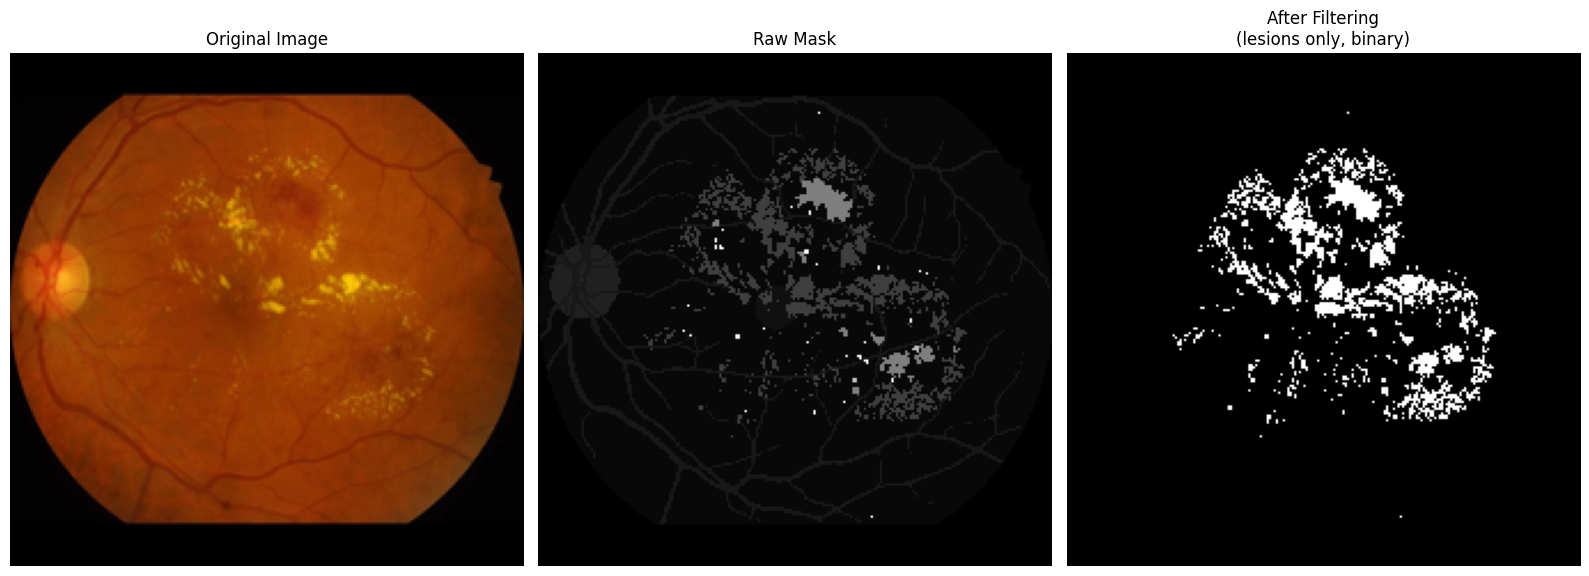

In [24]:
split_dir = IDRID_SPLIT_DIRS[0]
images_dir = os.path.join(split_dir, "Images")
labels_dir = os.path.join(split_dir, "Labels")

sample_img_path = sorted(glob.glob(os.path.join(images_dir, "*.jpg")))[0]

if os.path.normpath(split_dir) == os.path.normpath("/data/aveera/Refined IDRiD/Train/Train"):
    image_id = os.path.splitext(os.path.basename(sample_img_path))[0] + "_vessel"
else:
    image_id = os.path.splitext(os.path.basename(sample_img_path))[0]

sample_mask_path = os.path.join(labels_dir, f"{image_id}.png")
target_size = (224, 224)

raw_img = np.array(Image.open(sample_img_path).convert('RGB').resize(target_size))
raw_mask_native = np.array(Image.open(sample_mask_path).convert('L'))

raw_mask = cv2.resize(raw_mask_native, target_size, interpolation=cv2.INTER_NEAREST)

lesion_only_mask = np.isin(raw_mask, list(LESION_LABEL_IDS)).astype(np.uint8)

print(f"Sample: {image_id}")
print(f"Unique label values in raw mask: {sorted(np.unique(raw_mask).tolist())}")
print(f"Lesion pixels after filtering: {lesion_only_mask.mean():.2%} of image")
print(f"Lesion pixel count: {lesion_only_mask.sum()}")

fig, axes = plt.subplots(1, 3, figsize=(16, 6))

axes[0].imshow(raw_img)
axes[0].set_title("Original Image")
axes[0].axis("off")

axes[1].imshow(raw_mask, cmap="gray")
axes[1].set_title("Raw Mask")
axes[1].axis("off")

axes[2].imshow(lesion_only_mask, cmap="gray", vmin=0, vmax=1)
axes[2].set_title("After Filtering\n(lesions only, binary)")
axes[2].axis("off")

plt.tight_layout()
plt.show()

**This function fetches the weights for the model saved from the drive and loads them into the appropriate model.**

In [25]:
def load_model(model_name, weight_path, device):
    """Load the model given the model weights"""
    if model_name == "resnet50":
        model = models.resnet50(weights=None)
        num_features = model.fc.in_features
        model.fc = nn.Sequential(nn.Dropout(0.4), nn.Linear(num_features, 5))
    elif model_name == "efficientnetb0":
        model = models.efficientnet_b0(weights=None)
        num_features = model.classifier[1].in_features
        model.classifier = nn.Sequential(nn.Dropout(0.4), nn.Linear(num_features, 5))
    else:
        raise ValueError(f"Unknown model_name: {model_name}")

    model.load_state_dict(torch.load(weight_path, map_location=device))
    model = model.to(device)
    model.eval()
    return model

In [26]:
class_names = ["No DR", "Mild DR","Moderate DR", "Severe DR","Proliferative DR"]

In [27]:
idrid_loader = DataLoader(
    idrid_subset,
    batch_size=32,
    shuffle=True,
    num_workers=4,
    pin_memory=True,
    persistent_workers=True,
    drop_last=True
)

**While Grad-CAM is widely applied in DR interpretability literature, disclosed hyperparameters for perturbation-based methods (LIME, SHAP) are rarely reported in DR-specific work.**

Our parameter choices were therefore informed by broader medical-imaging and XAI benchmarking literature rather than DR-specific research, while also accoutning for our resource constraints given the scale of our evaluation.

**For LIME, we set lime_samples=1000**, consistent with values used in [Gastrointestinal Endoscopic study](https://arxiv.org/pdf/2503.00780), [Sickle Cell study](https://arxiv.org/pdf/2305.01663) and [Photonic Chip study](https://arxiv.org/pdf/2505.09266) which set the number of samples to 1000 to ensure the creation of a sufficient number of perturbed samples around the input instance for accurate approximation.

**For SHAP, we set the max_evals =500**, consistent with the [Sickle Cell study](https://arxiv.org/pdf/2305.01663) from above and is also the SHAP libraries default. We also use batch_size-50 which is the SHAP library, the same justification as this study [haematopoietic stem cell study](https://pmc.ncbi.nlm.nih.gov/articles/PMC12746025/)


**We use a 32x32 blur kernel for the SHAP masker, smaller than the 128x128 kernel used in SHAP's reference examples for 224x224 natural images.** In natural-image classification, the relevant object typically occupies a large contiguous region of the frame whereas for DR lesion attribution, multiple small lesions can appear simultaneously across the image. A 128x128 kernel would blur across a majority of the image width in a single masking operation, conflating spatially distinct lesions that should be attributed independently, which is why we choose 32x32

**The XAI Attribution Engine is a single wrapper around three XAI methods, so each trained model can be explained the same way regardless of which method is used. Given a model and an image, it returns an attribution map per method highlighting the regions that most influenced the prediction**

In [28]:
class AttributionEngine:
    IMAGENET_MEAN = np.array([0.485, 0.456, 0.406], dtype=np.float32)
    IMAGENET_STD  = np.array([0.229, 0.224, 0.225], dtype=np.float32)
    CLASS_NAMES = ["No DR","Mild DR","Moderate DR","Severe DR", "Proliferative DR"]

    def __init__(self, model, device, lime_samples=1000, img_size=224, shap_max_evals=500, shap_batch_size=50):
        self.model = model.to(device)
        self.model.eval()
        self.device = device

        self.lime_samples    = lime_samples     # How many perturbed versions of the image LIME generates to fit its local surrogate model
        self.img_size        = img_size
        self.shap_max_evals  = shap_max_evals   # How many masked evaluations shap.Explainer's Partition explainer is allowed per image
        self.shap_batch_size = shap_batch_size  # Batch size used when shap.Explainer evaluates masked images through the model
        self.class_names     = self.CLASS_NAMES

        self._gradcam = None

        self._norm_transform = transforms.Normalize(mean=self.IMAGENET_MEAN.tolist(), std=self.IMAGENET_STD.tolist()) # Stores the standard ImageNet normalization
        self.shap_explainer = None  # Built lazily on first compute_shap() call, once we know the image shape
        self.lime_explainer = lime_image.LimeImageExplainer()

    def find_gradcam_target_layer(self):
      if hasattr(self.model, "layer4"):
          target_layer = self.model.layer4[-1]
          layer_desc = "self.model.layer4[-1] (last residual block)"
      elif hasattr(self.model, "features"):
          target_layer = self.model.features[-1]
          layer_desc = "self.model.features[-1] (last conv+BN+activation block)"
      else:
          conv_layers = [m for m in self.model.modules() if isinstance(m, nn.Conv2d)]
          if not conv_layers:
              raise ValueError("Could not locate a Conv2d layer in the model for Grad-CAM.")
          target_layer = conv_layers[-1]
          layer_desc = ("Last convolutional layer. It is a raw convolutional layer")
      return target_layer

    # Builds a Grad-CAM object
    def get_gradcam(self):
        if self._gradcam is None:
            target_layer = self.find_gradcam_target_layer()
            self._gradcam = GradCAM(model=self.model, target_layers=[target_layer])
        return self._gradcam

    def unnormalize_to_uint8(self, img_tensor):
        """Unormalizes the image for LIME and SHAP (since they need the original image to create their superpixels)"""
        img = img_tensor.detach().cpu().numpy().transpose(1, 2, 0)
        img = img * self.IMAGENET_STD + self.IMAGENET_MEAN
        img = np.clip(img, 0.0, 1.0)
        return (img * 255).astype(np.uint8)

    @staticmethod
    def normalize_map(m, pct_clip=99.0, mode="abs"):
        m = np.nan_to_num(m.astype(np.float32))
        if mode == "abs":
            m = np.abs(m)
        elif mode == "pos":
            m = np.clip(m, 0, None)
        else:
            raise ValueError(f"Unknown normalize mode: {mode!r} (expected 'abs' or 'pos')")

        if m.max() > 0:
            clip_val = np.percentile(m, pct_clip)
            if clip_val > 0:
                m = np.clip(m, 0, clip_val)
        mn, mx = m.min(), m.max()
        if mx - mn > 1e-12:
            m = (m - mn) / (mx - mn)
        else:
            m = np.zeros_like(m)
        return m

    def resize_map(self, m):
        """Grad-CAM generally produces a smaller image, so the image is resized back to a normal viewing standard (224 x 224 pixels)"""
        if m.shape[0] != self.img_size or m.shape[1] != self.img_size:
            m = cv2.resize(m.astype(np.float32), (self.img_size, self.img_size), interpolation=cv2.INTER_LINEAR)
        return m

    def compute_gradcam(self, img, target_class):
        """Computes and returns the Grad-CAM heatmap"""
        cam = self.get_gradcam()
        targets = [ClassifierOutputTarget(target_class)]
        grayscale_cam = cam(input_tensor=img, targets=targets)[0]
        heatmap = self.normalize_map(grayscale_cam, mode="abs")
        return self.resize_map(heatmap)

    def show_grad_cam(self, img, raw_img_uint8, target_class):
        """Displays the GradCAM heatmap"""
        heatmap = self.compute_gradcam(img, target_class)
        fig, axes = plt.subplots(1, 2, figsize=(10, 5))
        axes[0].imshow(raw_img_uint8)
        axes[0].set_title("Original Image")
        axes[0].axis("off")
        axes[1].imshow(raw_img_uint8)
        axes[1].imshow(heatmap, cmap='jet', alpha=0.5)
        axes[1].set_title("Grad-CAM")
        axes[1].axis("off")
        plt.tight_layout()
        plt.show()

    def _lime_predict_fn(self, numpy_images):
        """Returns the model's raw logits as a numpy array"""
        tensor = torch.from_numpy(numpy_images).float().to(self.device)
        tensor = tensor / 255.0
        tensor = tensor.permute(0, 3, 1, 2)
        tensor = self._norm_transform(tensor)

        with torch.no_grad():
            logits = self.model(tensor)

        return logits.cpu().numpy()

    def compute_lime(self, raw_img_uint8, target_class):
        """Runs LIME once, returns the raw explanation object."""
        np.random.seed(SEED)
        random.seed(SEED)
        torch.manual_seed(SEED)

        explanation = self.lime_explainer.explain_instance(
            raw_img_uint8.astype('double'),
            self._lime_predict_fn,
            top_labels=5,
            hide_color=0, # Uses a flat black baseline to represent "hidden" superpixels, following the library's default
            num_samples=self.lime_samples,
        )

        if target_class not in explanation.local_exp:
            raise ValueError(
                f"LIME did not explain class {target_class} "
                f"(only explained {list(explanation.local_exp.keys())}); increase top_labels."
            )
        return explanation

    import matplotlib.pyplot as plt

    def get_lime_heatmap(self, explanation, target_class):
        """LIME heatmaps for Pointing Game"""
        dict_heatmap = dict(explanation.local_exp[target_class])
        heatmap = np.vectorize(dict_heatmap.get)(explanation.segments)
        heatmap = self.normalize_map(heatmap, mode="pos")
        return self.resize_map(heatmap)

    def show_lime(self, raw_img_uint8, target_class, num_features=5, positive_only=True):
        """Displays the LIME maps."""
        explanation = self.compute_lime(raw_img_uint8, target_class)

        fig, axes = plt.subplots(1, 4, figsize=(22, 5))
        fig.suptitle(f"LIME Detailed Subpixel Diagnostics: {type(self.model).__name__} (Class {target_class})",fontsize=14, weight='bold', y=1.02)

        # Original image
        axes[0].imshow(raw_img_uint8)
        axes[0].set_title("Original Image Structure")
        axes[0].axis("off")

        # Positive-only masking, using the method's own parameters
        temp1, mask1 = explanation.get_image_and_mask(
            target_class, positive_only=positive_only, num_features=num_features, hide_rest=True
        )
        axes[1].imshow(mark_boundaries(temp1 / 255.0, mask1))
        axes[1].set_title(f"Top {num_features} {'Positive' if positive_only else 'Pos/Neg'} Features")
        axes[1].axis("off")

        # Pros & cons boundary (fixed at 10 features, both signs, rest shown)
        temp2, mask2 = explanation.get_image_and_mask(
            target_class, positive_only=False, num_features=10, hide_rest=False
        )
        axes[2].imshow(mark_boundaries(temp2 / 255.0, mask2))
        axes[2].set_title("Top 10 Pros/Cons Boundary")
        axes[2].axis("off")

        # Symmetrical continuous weight heatmap
        dict_heatmap = dict(explanation.local_exp[target_class])
        heatmap_matrix = np.vectorize(dict_heatmap.get)(explanation.segments)

        max_val = np.abs(heatmap_matrix).max() if np.abs(heatmap_matrix).max() > 0 else 1.0
        im = axes[3].imshow(heatmap_matrix, cmap='RdBu', vmin=-max_val, vmax=max_val)
        axes[3].set_title("Symmetrical Weight Distribution")
        axes[3].axis("off")

        fig.colorbar(im, ax=axes[3], orientation='vertical', fraction=0.046, pad=0.04)

        plt.tight_layout()
        plt.show()

    def _shap_predict_fn(self, numpy_images):
        """Returns the model's raw logits as a numpy array"""
        tensor = torch.from_numpy(numpy_images).float().to(self.device)
        tensor = tensor / 255.0
        tensor = tensor.permute(0, 3, 1, 2)
        tensor = self._norm_transform(tensor)

        with torch.no_grad():
            logits = self.model(tensor)

        return logits.cpu().numpy()

    def _build_shap_explainer(self, image_shape):
        """Builds the SHAP explainer object."""
        np.random.seed(SEED)
        random.seed(SEED)
        torch.manual_seed(SEED)
        masker_blur = shap.maskers.Image("blur(32,32)", image_shape)
        self.shap_explainer = shap.Explainer(self._shap_predict_fn, masker_blur, output_names=self.class_names)

    def compute_shap(self, raw_img_uint8, target_class=None, all_classes=True):
        """Return the SHAP values for the given image."""
        np.random.seed(SEED)
        random.seed(SEED)
        torch.manual_seed(SEED)

        if self.shap_explainer is None:
            self._build_shap_explainer(raw_img_uint8.shape)

        images_batch = raw_img_uint8[np.newaxis, ...]
        n_classes = len(self.class_names) if self.class_names else 5
        outputs = list(range(n_classes)) if all_classes else [target_class]

        return self.shap_explainer(images_batch,max_evals=self.shap_max_evals,batch_size=self.shap_batch_size,outputs=outputs,)

    def get_shap_heatmap(self, shap_values, class_position=0):
        """SHAP heatmaps for Pointing Game"""
        raw_shap = shap_values.values[0, :, :, :, class_position]
        sv_signed = raw_shap.sum(axis=-1)
        heatmap = self.normalize_map(sv_signed, mode="pos")
        return self.resize_map(heatmap), self.resize_map(sv_signed)

    def show_shap(self, raw_img_uint8, target_class=None, all_classes=True):
        """Visualizes SHAP values using SHAP's own built-in image_plot."""
        shap_values = self.compute_shap(raw_img_uint8, target_class=target_class, all_classes=all_classes)
        shap.image_plot(shap_values)

    def compute_all(self, img_tensor, label):
        """Runs all the XAI techniques at once, returns a dictionary with the results."""
        self.model.eval()
        img = img_tensor.unsqueeze(0).to(self.device)

        with torch.no_grad():
            pred = self.model(img).argmax(dim=1).item()

        raw_img_uint8 = self.unnormalize_to_uint8(img_tensor)

        gradcam_map = self.compute_gradcam(img, pred)

        lime_explanation = self.compute_lime(raw_img_uint8, pred)
        lime_map = self.get_lime_heatmap(lime_explanation, pred)

        shap_values = self.compute_shap(raw_img_uint8, target_class=pred, all_classes=False)
        shap_map, sv_signed = self.get_shap_heatmap(shap_values, class_position=0)

        return {'lime': lime_map, 'shap': shap_map, 'visual_shap': sv_signed, 'gradcam': gradcam_map, 'pred': pred}

In [29]:
_engine_cache = {}

def get_engine_for(model):
    """Look up the AttributionEngine that was built for this exact model object."""

    eng = _engine_cache.get(id(model))
    if eng is None:
        raise RuntimeError(
            "No AttributionEngine registered for this model."
        )
    return eng


In [30]:
test_transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

In [31]:
def run_attributions_on_samples(engine, samples, transform, desc="XAI"):
    results = {'lime': [], 'shap': [], 'gradcam': [], 'labels': []}
    for raw_img, label in tqdm(samples, desc=desc, ncols=90):
        img_tensor = transform(PILImage.fromarray(raw_img))
        maps = engine.compute_all(img_tensor, label)
        results['lime'].append(maps['lime'])
        results['shap'].append(maps['shap'])
        results['gradcam'].append(maps['gradcam'])
        results['labels'].append(label)
    return results

# **Side-by-Side Comparison of each XAI technique**

--- resnet50 ---


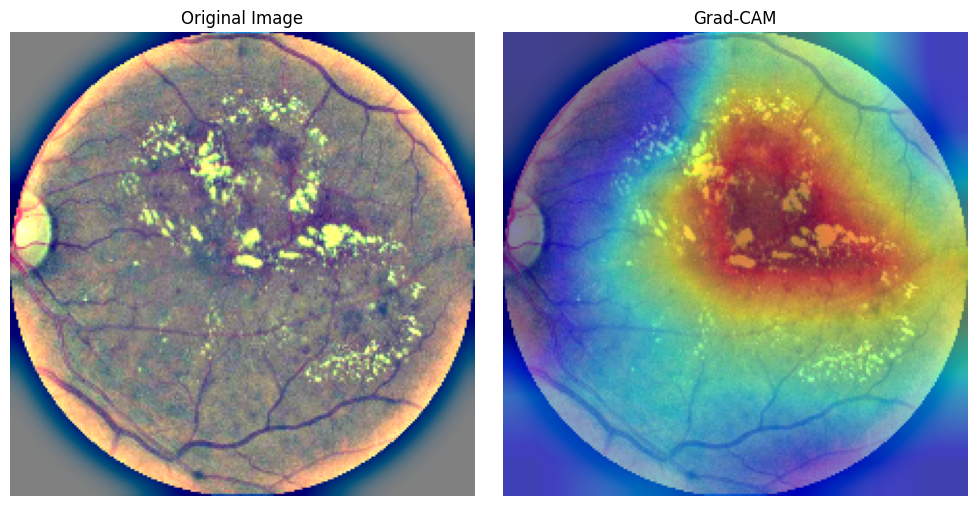


  0%|          | 0/498 [00:00<?, ?it/s]


 99%|█████████▉| 492/498 [00:00<00:00, 2251.60it/s]

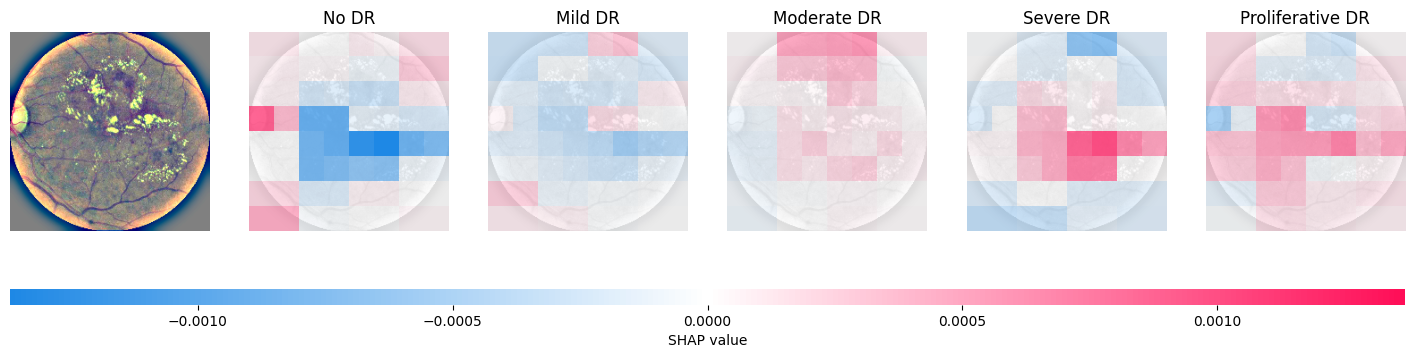


  0%|          | 0/1000 [00:00<?, ?it/s]


  1%|          | 10/1000 [00:00<01:04, 15.42it/s]


  2%|▏         | 20/1000 [00:00<00:34, 28.34it/s]


  3%|▎         | 30/1000 [00:00<00:24, 39.21it/s]


  4%|▍         | 40/1000 [00:01<00:20, 47.56it/s]

...


 97%|█████████▋| 970/1000 [00:15<00:00, 62.42it/s]


 98%|█████████▊| 980/1000 [00:15<00:00, 62.84it/s]


 99%|█████████▉| 990/1000 [00:15<00:00, 62.83it/s]


100%|██████████| 1000/1000 [00:15<00:00, 62.29it/s]


100%|██████████| 1000/1000 [00:15<00:00, 62.60it/s]

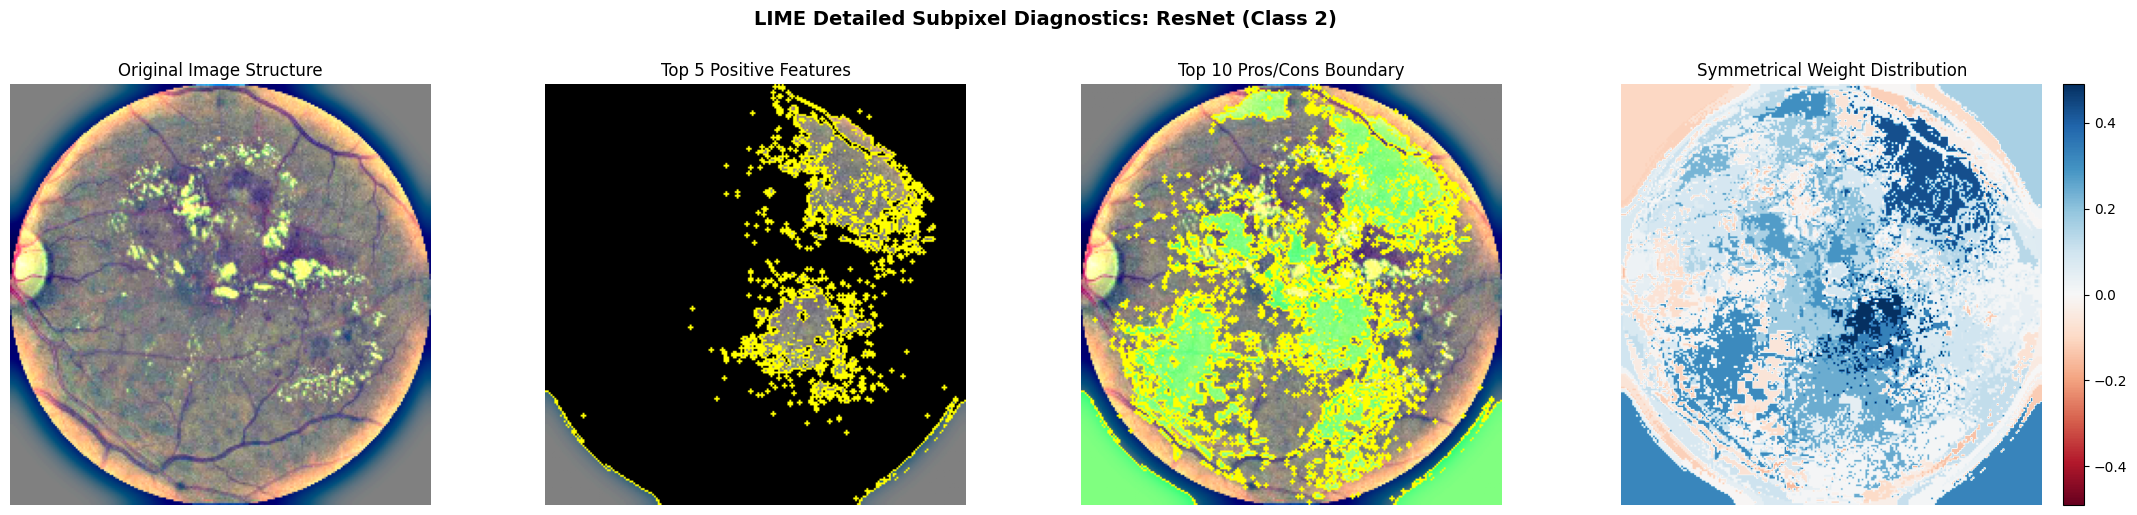

--- efficientnetb0 ---


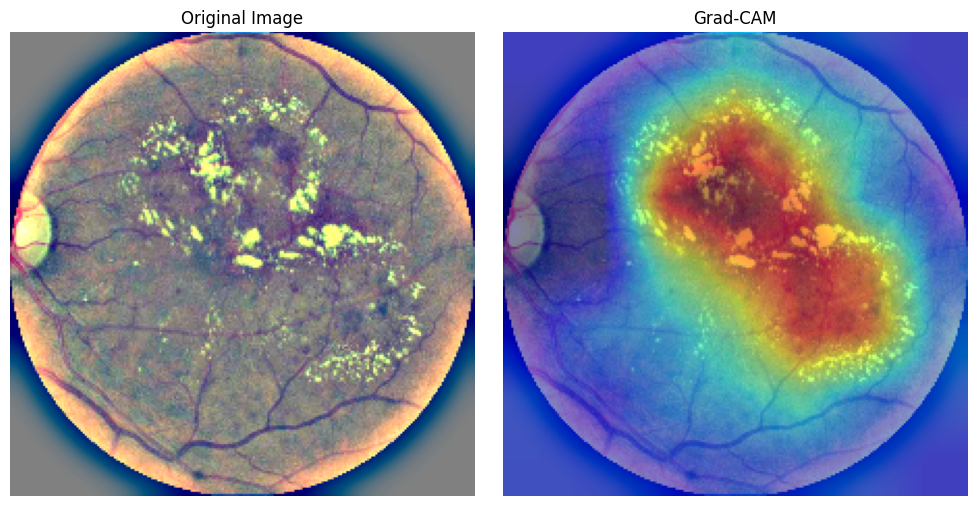


  0%|          | 0/498 [00:00<?, ?it/s]


 25%|██▍       | 124/498 [00:04<00:13, 27.39it/s]


 35%|███▍      | 174/498 [00:04<00:07, 41.44it/s]


 45%|████▍     | 224/498 [00:04<00:04, 59.76it/s]


 55%|█████▌    | 274/498 [00:04<00:02, 82.74it/s]

...


 85%|████████▌ | 424/498 [00:05<00:00, 177.15it/s]


 95%|█████████▌| 474/498 [00:05<00:00, 212.36it/s]


524it [00:05, 246.73it/s]                         


PartitionExplainer explainer: 100%|██████████| 1/1 [00:00<?, ?it/s]


PartitionExplainer explainer: 2it [00:16, 16.30s/it]               

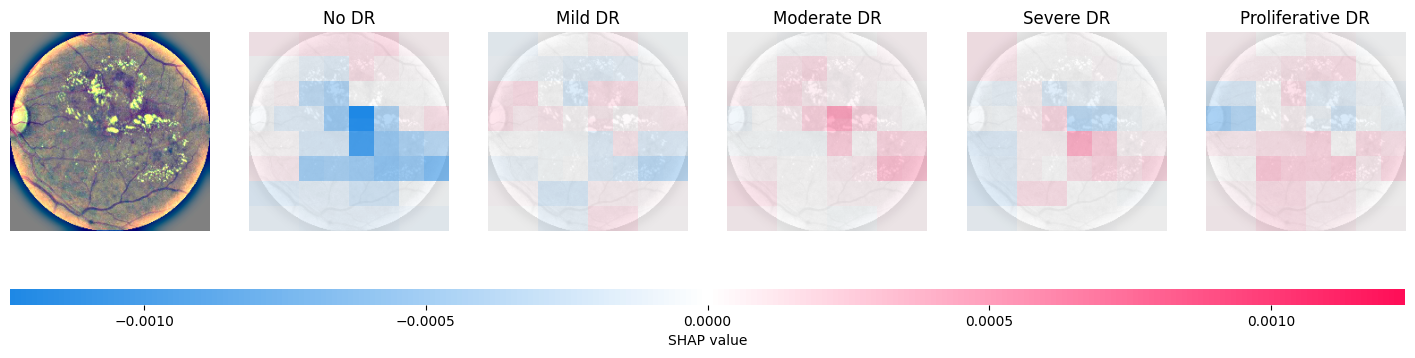


  0%|          | 0/1000 [00:00<?, ?it/s]


  1%|          | 10/1000 [00:02<03:32,  4.66it/s]


  2%|▏         | 20/1000 [00:02<01:34, 10.40it/s]


  3%|▎         | 30/1000 [00:02<00:56, 17.25it/s]


  4%|▍         | 40/1000 [00:02<00:38, 24.89it/s]

...


 97%|█████████▋| 970/1000 [00:14<00:00, 77.06it/s]


 98%|█████████▊| 980/1000 [00:14<00:00, 77.61it/s]


 99%|█████████▉| 990/1000 [00:14<00:00, 77.32it/s]


100%|██████████| 1000/1000 [00:14<00:00, 76.93it/s]


100%|██████████| 1000/1000 [00:14<00:00, 67.12it/s]

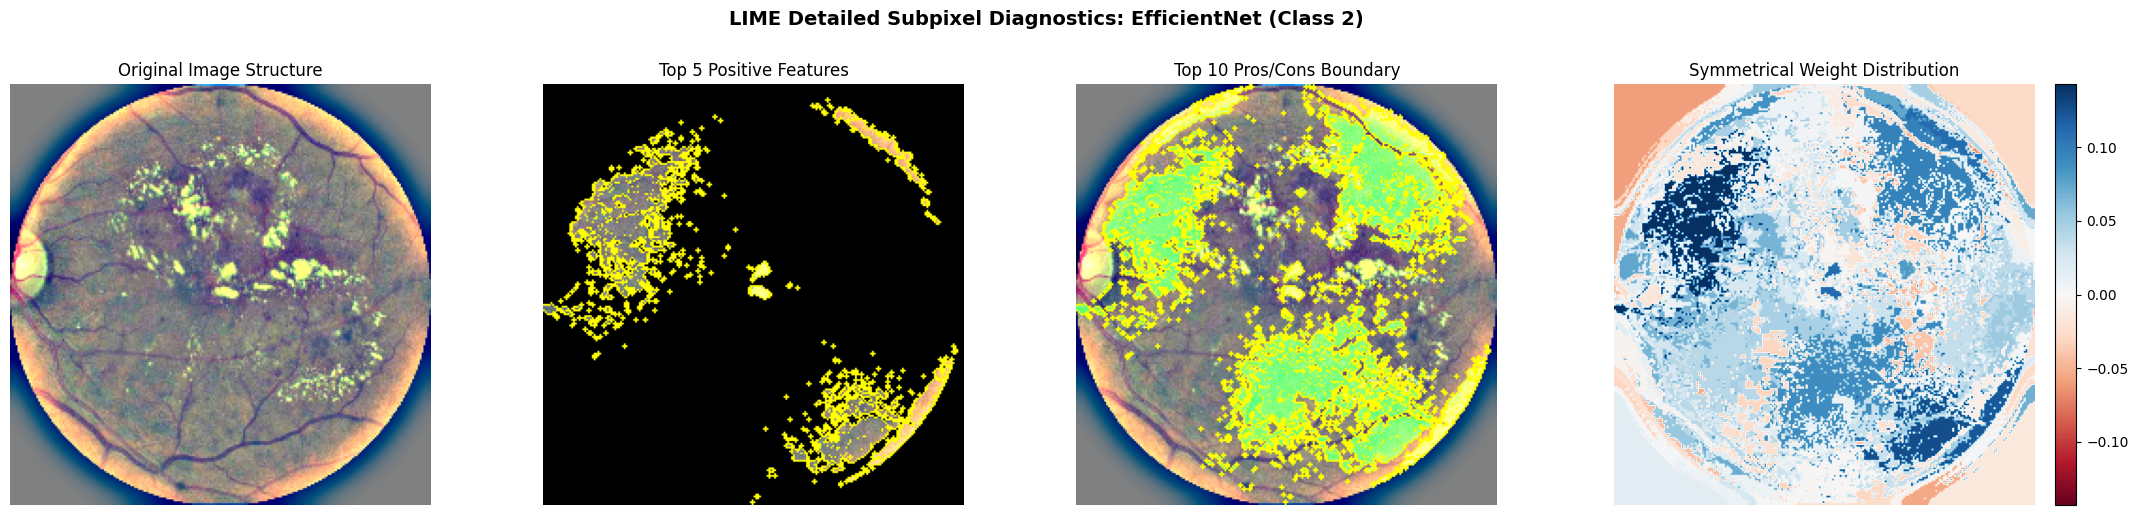

In [32]:
raw_image, lesion_mask = idrid_subset[0] # Sample image
drive_model_dir = "/data/aveera/models"
# xai_maps = {}

for model_name in ["resnet50","efficientnetb0"]:
  drive_weight_path = os.path.join(drive_model_dir, f"{model_name}_best_model.pth")
  model = load_model(model_name, drive_weight_path, device)

  engine = AttributionEngine(model, device)
  # Initialize SHAP background for the current engine
  _engine_cache[id(model)] = engine  # register so explain_* (MaxSensitivity) can find this engine later

  image_tensor = test_transform(PILImage.fromarray(raw_image))
  with torch.no_grad():
    predicted_class = model(image_tensor.unsqueeze(0).to(device)).argmax(dim=1).item()

  # Compute all heatmaps for downstream metrics (Pointing Game, IROF, etc.)
  # xai_maps[model_name] = engine.compute_all(image_tensor, predicted_class)

  # Visual display for this model
  raw_img_uint8 = engine.unnormalize_to_uint8(image_tensor)
  img_batched = image_tensor.unsqueeze(0).to(device)

  print(f"--- {model_name} ---")
  engine.show_grad_cam(img_batched, raw_img_uint8, predicted_class)
  engine.show_shap(raw_img_uint8, target_class=predicted_class, all_classes=True)
  engine.show_lime(raw_img_uint8, target_class=predicted_class)

# print("Computed attribution maps for:",list(xai_maps.keys()))

# **Part Three: Explainability Evaluation Metrics**

# **Localization Evaluation: The pointing game and IoU**


**Pointing Game**: Takes the single highest-attribution pixel in the explanation map and checks if it falls inside the ground-truth lesion region. Scores 1 if yes, 0 if no. It's a strict, all-or-nothing test of whether the model's single most important pixel is disease-relevant.

**IoU**: Measures a model's localization performance by calculating the ratio of the overlap area to the combined total area of the predicted bounding box and the ground-truth bounding box


In [33]:
import os
import numpy as np

N_TEST = 2
SAVE_DIR = "/data/aveera/xai_maps"
os.makedirs(SAVE_DIR, exist_ok=True)

test_samples = idrid_subset[:N_TEST]

attribution_maps_by_model = {}

for model_name in ["resnet50", "efficientnetb0"]:
    print(f"\n{'='*60}\n  Computing attribution maps | Model: {model_name}\n{'='*60}")

    drive_weight_path = os.path.join(drive_model_dir, f"{model_name}_best_model.pth")
    model = load_model(model_name, drive_weight_path, device)

    engine = AttributionEngine(model, device)
    _engine_cache[id(model)] = engine

    attribution_results = run_attributions_on_samples(engine, test_samples, test_transform, desc=f"XAI maps ({model_name})")

    gts           = np.stack(attribution_results['labels'], axis=0)
    gradcam_maps  = np.stack(attribution_results['gradcam'], axis=0)
    lime_maps     = np.stack(attribution_results['lime'], axis=0)
    shap_maps     = np.stack(attribution_results['shap'], axis=0)

    attribution_maps_by_model[model_name]= {'gts': gts, 'gradcam': gradcam_maps, 'lime': lime_maps, 'shap': shap_maps,}

    save_path = os.path.join(SAVE_DIR, f"attribution_maps_{model_name}_test.npz")
    np.savez(save_path, gts=gts, gradcam=gradcam_maps, lime=lime_maps, shap=shap_maps)
    print(f"Saved {N_TEST} images' attribution maps to {save_path}")


  Computing attribution maps | Model: resnet50



XAI maps (resnet50):   0%|                                          | 0/2 [00:00<?, ?it/s]


  0%|          | 0/1000 [00:00<?, ?it/s]


  0%|          | 5/1000 [00:00<00:25, 38.98it/s]


  1%|          | 9/1000 [00:00<00:27, 36.22it/s]

...


100%|██████████| 1000/1000 [00:16<00:00, 61.11it/s]


100%|██████████| 1000/1000 [00:16<00:00, 62.28it/s]


XAI maps (efficientnetb0): 100%|████████████████████████████| 2/2 [00:40<00:00, 20.06s/it]


XAI maps (efficientnetb0): 100%|████████████████████████████| 2/2 [00:40<00:00, 20.24s/it]

Saved 2 images' attribution maps to /data/aveera/xai_maps/attribution_maps_efficientnetb0_test.npz


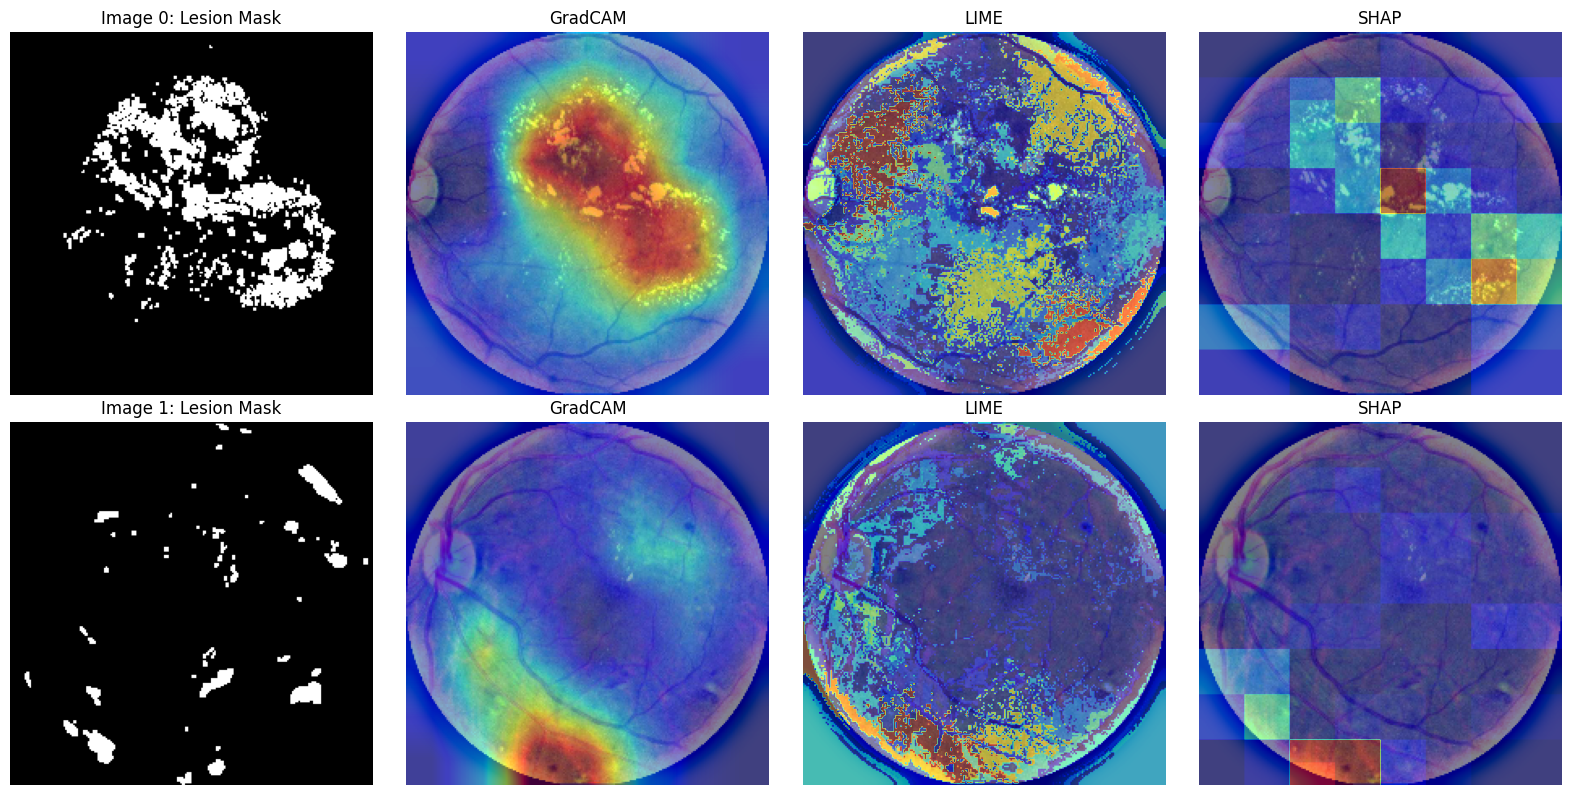

In [34]:
import numpy as np
import matplotlib.pyplot as plt

data = np.load(os.path.join(SAVE_DIR, "attribution_maps_efficientnetb0_test.npz"))
gts, gradcam_maps, lime_maps, shap_maps = data['gts'], data['gradcam'], data['lime'], data['shap']

raw_images = np.stack([img for img, _ in test_samples], axis=0)

n = gts.shape[0]
fig, axes = plt.subplots(n, 4, figsize=(16, 4 * n))
if n == 1:
    axes = axes[None, :]

for i in range(n):
    axes[i, 0].imshow(gts[i], cmap='gray')
    axes[i, 0].set_title(f"Image {i}: Lesion Mask")
    axes[i, 0].axis('off')

    for j, (name, m) in enumerate([("GradCAM", gradcam_maps[i]),
                                    ("LIME", lime_maps[i]),
                                    ("SHAP", shap_maps[i])], start=1):
        axes[i, j].imshow(raw_images[i])
        axes[i, j].imshow(m, cmap='jet', alpha=0.5)
        axes[i, j].set_title(name)
        axes[i, j].axis('off')

plt.tight_layout()
plt.show()

**Fixed-percentile thresholding of saliency maps is common in DR localization literature (e.g., Gondal et al., 2017). However, because DR lesion sizes vary drastically across images, a fixed global threshold inevitably over- or under-segments most cases. We instead adopt a per-image adaptive thresholding approach inspired by Schulz et al. (2020). For each image, the attribution map is binarized by selecting exactly the top-\(n\) highest-scored pixels, where \(n\) is equal to the ground-truth lesion pixel count for that specific image**

In [35]:
import numpy as np
import pandas as pd
import xaibenchmark as xb

def binarize_map_adaptive(attribution_map, gt_mask):
    """Schulz et al. (2020) style per-image adaptive thresholding."""
    m = np.asarray(attribution_map, dtype=np.float32)
    n = int(np.asarray(gt_mask).sum())

    if n <= 0:
        return np.zeros_like(m, dtype=np.uint8)
    if n >= m.size:
        return (m > 0).astype(np.uint8)

    top_k_frac = n / m.size
    cutoff = np.percentile(m, 100.0 * (1.0 - top_k_frac))
    return ((m >= cutoff) & (m > 0)).astype(np.uint8)

def binarize_map_batch(maps, gts):
    """Each map is thresholded using its own GT pixel count rather than a global threshold value."""
    assert maps.shape[0] == gts.shape[0]
    return np.stack([binarize_map_adaptive(maps[i], gts[i]) for i in range(maps.shape[0])], axis=0)

localization_rows = []

for model_name in ["resnet50", "efficientnetb0"]:
    load_path = os.path.join(SAVE_DIR, f"attribution_maps_{model_name}_test.npz")
    data = np.load(load_path)
    gts, gradcam_maps, lime_maps, shap_maps = data['gts'], data['gradcam'], data['lime'], data['shap']

    maps_dict = {"gradcam": gradcam_maps, "lime": lime_maps, "shap": shap_maps}

    print(f"=== {model_name} ===")
    for method, cont_maps in maps_dict.items():
        bin_maps = binarize_map_batch(cont_maps, gts)

        pointing_game = xb.hit(cont_maps, gts)
        iou_score = xb.iou(bin_maps, gts)

        print(f"--- {method} ---")
        print(f"Pointing Game           : {pointing_game:.4f}")
        print(f"IoU                     : {iou_score:.4f}\n")

        localization_rows.append({
            'model': model_name,
            'method': method,
            'pointing_game': round(pointing_game, 4),
            'iou': round(iou_score, 4),
        })

localization_df = pd.DataFrame(localization_rows)
display(localization_df)

=== resnet50 ===
--- gradcam ---
Pointing Game           : 1.0000
IoU                     : 0.1450

--- lime ---
Pointing Game           : 1.0000
IoU                     : 0.0320

--- shap ---
Pointing Game           : 0.0000
IoU                     : 0.0754

=== efficientnetb0 ===
--- gradcam ---
Pointing Game           : 1.0000
IoU                     : 0.1525

--- lime ---
Pointing Game           : 1.0000
IoU                     : 0.0575

--- shap ---
Pointing Game           : 1.0000
IoU                     : 0.1249



,model,method,pointing_game,iou
0,resnet50,gradcam,1.0,0.1450
1,resnet50,lime,1.0,0.0320
2,resnet50,shap,0.0,0.0754
3,efficientnetb0,gradcam,1.0,0.1525
4,efficientnetb0,lime,1.0,0.0575
5,efficientnetb0,shap,1.0,0.1249


In [36]:
RESULTS_DIR = "/data/aveera/results"
os.makedirs(RESULTS_DIR, exist_ok=True)
localization_df.to_csv(os.path.join(RESULTS_DIR, "localization_summary.csv"), index=False)
print(f"Saved localization summary to {os.path.join(RESULTS_DIR, 'localization_summary.csv')}")

Saved localization summary to /data/aveera/results/localization_summary.csv


In [37]:
_trapz = getattr(np, "trapezoid", None) or np.trapz

In [38]:
def load_attribution_maps(save_dir, model_name, filename_template="attribution_maps_{model}_test.npz"):
    """Loads precomputed attribution maps for one model from disk."""
    data = np.load(os.path.join(save_dir, filename_template.format(model=model_name)))
    method_maps = {
        "LIME": data['lime'],
        "GradCAM": data['gradcam'],
        "SHAP": data['shap'],
    }
    return method_maps


In [39]:
def get_predicted_labels(model, samples, device, transform=test_transform):
    """Recomputes the model's predicted class per sample."""
    preds = []
    model.eval()
    with torch.no_grad():
        for raw_img_np, _ in samples:
            input_tensor = transform(PILImage.fromarray(raw_img_np)).unsqueeze(0).to(device)
            pred = model(input_tensor).argmax(dim=1).item()
            preds.append(pred)
    return np.array(preds)

# **Faithfulness Evaluation: IROF**

Gradually remove the image regions identified as most important by the XAI method. If the model's confidence drops significantly, it shows those regions were genuinely important, meaning the explanation is more faithful.

**The original IROF paper uses SLIC to segment images into regions**

In [40]:
class FastIROF:
    def __init__(self, model, device, n_segments=100, compactness=10, sigma=1, max_regions=100):
        """Initialize IROF evaluator with model and segmentation parameters"""
        self.model = model.to(device)
        self.device = device
        self.n_segments = n_segments    # SLIC: approximate target number of segments
        self.compactness = compactness  # SLIC: balances color proximity vs. spatial proximity
        self.sigma = sigma              # Gaussian smoothing applied before segmenting
        self.max_regions = max_regions  # Max number of regions to evaluate

        # ImageNet normalization stats used to invert test_transform before segmenting,
        # so SLIC sees real pixel colours/edges instead of normalized (mean-0) values.
        self._imagenet_mean = np.array([0.485, 0.456, 0.406])
        self._imagenet_std = np.array([0.229, 0.224, 0.225])

    def perturb(self, image, mask):
        """Replace selected region in the image with the image's average color (baseline)"""
        baseline = image.mean(dim=[2, 3], keepdim=True)
        image = image.clone()

        if mask.shape != (image.shape[2], image.shape[3]):
            raise ValueError(f"Mask shape {mask.shape} does not match image shape {(image.shape[2], image.shape[3])}")

        mask = mask.unsqueeze(0).unsqueeze(0)  # Add batch and channel dims
        mask = mask.expand_as(image)  # Match shape to image

        # Apply perturbation: replace masked area with baseline
        image = torch.where(mask.bool(), baseline, image)
        return image

    def segment_image(self, x):
        """Segment the original input image (not the attribution map)"""
        img_np = x.squeeze(0).permute(1, 2, 0).cpu().numpy()
        img_np = img_np * self._imagenet_std + self._imagenet_mean  # undo normalization
        img_np = np.clip(img_np, 0.0, 1.0)

        segments = slic(
            img_np.astype(np.float64),
            n_segments=self.n_segments,
            compactness=self.compactness,
            sigma=self.sigma,
            channel_axis=-1,   # img_np is now a real 3-channel RGB image, not a 1-channel map
            start_label=0,
        )
        return segments

    def apply(self, x, a, y, segments, batch_size=8, order="morf", seed=42):
        """order="morf" (Most-Relevant-First) removes regions in DECREASING order of attribution score
        order="random" removes regions in a fixed random order and is only meant to used as a baseline to compare against"""
        if order not in ("morf", "random"):
            raise ValueError(f"order must be 'morf' or 'random', got {order!r}")

        x = x.to(self.device)
        y = y.to(self.device)

        a = a.squeeze()
        if a.ndim == 3:
            a = a.mean(axis=0)

        if a.shape != (x.shape[2], x.shape[3]):
            raise ValueError(f"Attribution shape {a.shape} does not match image size {(x.shape[2], x.shape[3])}")
        if segments.shape != (x.shape[2], x.shape[3]):
            raise ValueError(f"Segments shape {segments.shape} does not match image size {(x.shape[2], x.shape[3])}")

        # Get original model score for the target class
        with torch.no_grad():
            output = self.model(x)
            orig_score = F.softmax(output, dim=1) * y  # Element-wise multiplication with target mask
            orig_score = orig_score.sum().item()

        # Compute average ATTRIBUTION value within each (fixed, image-derived) region --
        region_scores = [(seg_id, a[segments == seg_id].mean()) for seg_id in np.unique(segments)]

        if order == "morf":
            # Sort by attribution score, HIGHEST first -- remove the regions the
            # explanation thinks are most important first. This is what makes it IROF.
            region_scores.sort(key=lambda pair: pair[1], reverse=True)
        else:  # order == "random"
            rng = np.random.RandomState(seed)
            rng.shuffle(region_scores)

        # Optionally limit number of evaluated regions
        if len(region_scores) > self.max_regions:
            region_scores = region_scores[:self.max_regions]

        scores = [orig_score]
        perturbed_images = []

        # This is used to continually carry over all the pertubations
        cumulative_mask = np.zeros_like(segments, dtype=np.uint8)

        # Create perturbed versions of the image by masking out one region at a time
        for seg_id, _ in region_scores:

            cumulative_mask[segments == seg_id] = 1

            # mask = (segments == seg_id).astype(np.uint8)
            # mask_tensor = torch.from_numpy(mask).to(self.device)

            perturbed_images.append(self.perturb(x.clone(), torch.from_numpy(cumulative_mask).to(self.device)))

        # Stack all perturbed images into one batch
        perturbed_images = torch.stack(perturbed_images).squeeze(1)  # Shape: [num_regions, C, H, W]

        # Run model on all perturbed images and collect scores
        with torch.no_grad():
            for i in range(0, len(perturbed_images), batch_size):
                batch = perturbed_images[i:i + batch_size]
                output = self.model(batch)
                for out in output:
                    score = F.softmax(out, dim=0) * y.squeeze()
                    scores.append(score.sum().item())

        eps = 1e-8
        normalized_scores = [s / (orig_score + eps) for s in scores]

        return scores, normalized_scores, segments


def resample_curve(curve, n_points=21):
    x_orig = np.linspace(0, 1, len(curve))
    x_new = np.linspace(0, 1, n_points)
    return np.interp(x_new, x_orig, curve)

def plot_segments(image_np, segments, name=""):
    """Plot segmentation overlay on original image with custom method name"""
    plt.figure(figsize=(8, 6))
    plt.imshow(image_np[:segments.shape[0], :segments.shape[1]])  # Show original image
    plt.imshow(segments, cmap="jet", alpha=0.4)  # Overlay superpixels
    plt.title(f"SLIC Superpixel Overlay (IROF for {name})")
    plt.axis("off")
    plt.tight_layout()
    plt.show()

def plot_irof_scores(scores_sorted, scores_random, name=""):
    """Plot IROF score drop curve (sorted vs. random), legend placed safely"""
    plt.figure(figsize=(7, 5))
    plt.plot(scores_sorted, marker="o", label="Sorted by Attribution", linewidth=2)
    plt.plot(scores_random, marker="x", linestyle='--', label="Random Order", linewidth=1.5)
    plt.title(f"IROF Score Drop Comparison ({name})")
    plt.xlabel("Number of Removed Regions")
    plt.ylabel("Model Output Score")
    plt.grid(True)

    # Legend placed outside upper right
    plt.legend(loc='upper center', bbox_to_anchor=(0.5, -0.12), ncol=2, frameon=False)
    plt.tight_layout()
    plt.show()


In [41]:
def run_irof_on_image(irof_evaluator, raw_img_np, predicted_class, method_maps, img_idx,
                       num_classes=5, transform=test_transform):
    """Runs MoRF IROF for one image, across every attribution method."""

    input_tensor = transform(PILImage.fromarray(raw_img_np)).unsqueeze(0).to("cpu")

    out_max = torch.zeros(1, num_classes)
    out_max[0, predicted_class] = 1

    # Segment the original image once, reuse across all methods
    image_segments = irof_evaluator.segment_image(input_tensor)

    rows = []
    sorted_curves = {}
    random_curves = {}

    for method_name, maps_array in method_maps.items():
        attr_map = torch.tensor(maps_array[img_idx], dtype=torch.float32)

        _, norm_scores_sorted, _ = irof_evaluator.apply(x=input_tensor, a=attr_map, y=out_max,segments=image_segments, order="morf")
        _, norm_scores_random, _ = irof_evaluator.apply(x=input_tensor, a=attr_map, y=out_max,segments=image_segments, order="random")

        resampled_sorted = resample_curve(norm_scores_sorted)
        resampled_random = resample_curve(norm_scores_random)

        sorted_curves[method_name] = resampled_sorted
        random_curves[method_name] = resampled_random

        irof_auc = float(_trapz(resampled_sorted) / (len(resampled_sorted) - 1))

        rows.append({
            'method':          method_name,
            'image_index':     img_idx,
            'predicted_class': predicted_class,
            'irof_auc':        round(irof_auc, 4),
            'num_regions':     len(np.unique(image_segments))
        })

    return rows, sorted_curves, random_curves

In [42]:
def run_irof_evaluation(model, samples, predicted_labels, method_maps,
                         n_segments=100, compactness=10, sigma=1, max_regions=100,
                         desc="IROF"):
    """Runs the full IROF faithfulness evaluation over samples."""

    irof_evaluator = FastIROF(model=model, device="cpu", n_segments=n_segments,
                               compactness=compactness, sigma=sigma, max_regions=max_regions)

    all_rows = []
    curves = {m: [] for m in method_maps}
    random_curves = {m: [] for m in method_maps}

    for img_idx in tqdm(range(len(samples)), desc=desc, ncols=90):
        raw_img_np, _ = samples[img_idx]
        predicted_class = int(predicted_labels[img_idx])

        rows, sorted_curves_i, random_curves_i = run_irof_on_image(
            irof_evaluator, raw_img_np, predicted_class, method_maps, img_idx
        )

        all_rows.extend(rows)
        for method_name in method_maps:
            curves[method_name].append(sorted_curves_i[method_name])
            random_curves[method_name].append(random_curves_i[method_name])

    full_df = pd.DataFrame(all_rows)
    return full_df, curves, random_curves

# **Why max_regions=100?**
Limiting to 100 regions ensures a good balance between spatial resolution and runtime efficiency. This number is sufficient to capture meaningful attribution patterns without over-segmenting the image or introducing noise from very small, low-relevance regions. At the same time, it limits the number of model evaluations during IROF scoring, keeping runtime manageable.

This choice follows common practice (e.g., skimage library).

In [43]:
def summarize_and_save_irof(full_df, results_dir, tag="test"):
    """Aggregates per-image IROF results into a per-method summary."""

    summary = (full_df.groupby('method').agg(mean_irof_auc=('irof_auc', 'mean'), std_irof_auc=('irof_auc', 'std'),
             n_images=('irof_auc', 'count')).reset_index().sort_values('mean_irof_auc')
    )

    summary['mean_irof_auc'] = summary['mean_irof_auc'].round(4)
    summary['std_irof_auc'] = summary['std_irof_auc'].round(4)

    os.makedirs(results_dir, exist_ok=True)
    now = datetime.now().strftime("%Y-%m-%d")
    full_path = os.path.join(results_dir, f'irof_full_{tag}_{now}.csv')
    summary_path = os.path.join(results_dir, f'irof_summary_{tag}_{now}.csv')

    full_df.to_csv(full_path, index=False)
    summary.to_csv(summary_path, index=False)

    print(f"Saved per-image results to {full_path}")
    print(f"Saved summary to {summary_path}")

    return summary

In [44]:
def plot_irof_curves(curves, n_images, title_suffix=""):
    """Plots the mean score-drop curve per method."""

    plt.figure(figsize=(10, 6))
    n_resample_points = len(next(iter(curves.values()))[0])
    fraction_removed = np.linspace(0, 1, n_resample_points)

    for method_name, method_curves in curves.items():
        mean_curve = np.array(method_curves).mean(axis=0)
        plt.plot(fraction_removed, mean_curve, marker="o", markersize=3, label=method_name)

    plt.title(f"IROF Score Drop Comparison{title_suffix} ({n_images} images)")
    plt.xlabel("Fraction of Regions Removed")
    plt.ylabel("Mean Normalized Prediction Score (1.0 = original confidence)")
    plt.grid(True)
    plt.legend(loc='upper center', bbox_to_anchor=(0.5, -0.15), ncol=3, frameon=False)
    plt.tight_layout()
    plt.show()


def plot_irof_bar(summary, title_suffix=""):
    """Plots a bar chart of mean IROF AUC per method."""
    plt.figure(figsize=(7, 5))
    plt.bar(summary['method'], summary['mean_irof_auc'])
    plt.ylabel("Mean IROF AUC (normalized, lower = more faithful)")
    plt.title(f"Faithfulness Comparison by Attribution Method{title_suffix}")
    plt.grid(axis='y', alpha=0.3)
    plt.tight_layout()
    plt.show()


  Faithfulness (IROF) | Model: resnet50


Running faithfulness (IROF) test run on 2 images 



IROF:   0%|                                                         | 0/2 [00:00<?, ?it/s]


IROF:  50%|████████████████████████▌                        | 1/2 [00:11<00:11, 11.65s/it]


IROF: 100%|█████████████████████████████████████████████████| 2/2 [00:23<00:00, 11.81s/it]


IROF: 100%|█████████████████████████████████████████████████| 2/2 [00:23<00:00, 11.79s/it]


Collected 6 IROF measurements
Saved per-image results to /data/aveera/results/irof_full_resnet50_test_2026-09-09.csv
Saved summary to /data/aveera/results/irof_summary_resnet50_test_2026-09-09.csv

=== Faithfulness (IROF) summary | resnet50 ===
    (lower mean_irof_auc = confidence drops faster once top-attributed regions
     are removed = more faithful explanation)



,method,mean_irof_auc,std_irof_auc,n_images
2,SHAP,0.5245,0.1013,2
0,GradCAM,0.5451,0.0045,2
1,LIME,0.5956,0.1606,2


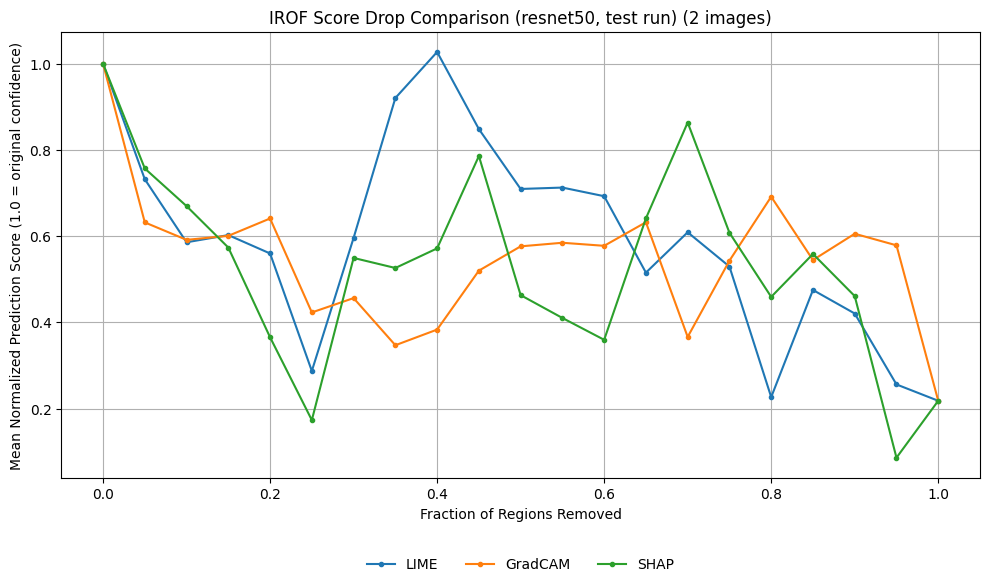

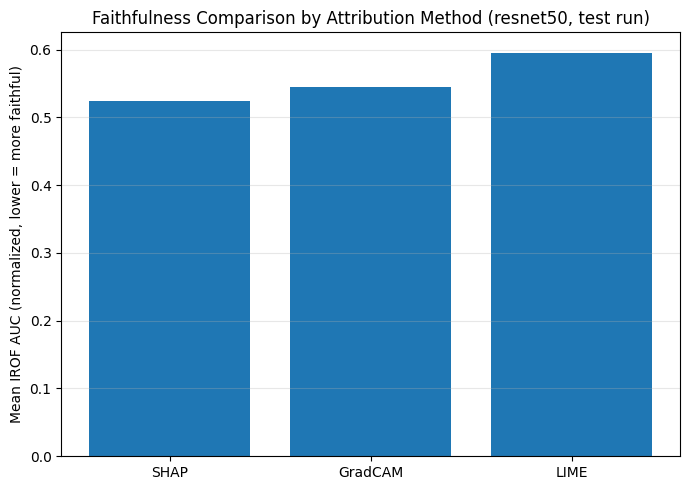


  Faithfulness (IROF) | Model: efficientnetb0


Running faithfulness (IROF) test run on 2 images 



IROF:   0%|                                                         | 0/2 [00:00<?, ?it/s]

[W909 13:22:41.978041372 NNPACK.cpp:61] Could not initialize NNPACK! Reason: Unsupported hardware.



IROF:  50%|████████████████████████▌                        | 1/2 [00:07<00:07,  7.83s/it]


IROF: 100%|█████████████████████████████████████████████████| 2/2 [00:15<00:00,  7.44s/it]


IROF: 100%|█████████████████████████████████████████████████| 2/2 [00:15<00:00,  7.50s/it]


Collected 6 IROF measurements
Saved per-image results to /data/aveera/results/irof_full_efficientnetb0_test_2026-09-09.csv
Saved summary to /data/aveera/results/irof_summary_efficientnetb0_test_2026-09-09.csv

=== Faithfulness (IROF) summary | efficientnetb0 ===
    (lower mean_irof_auc = confidence drops faster once top-attributed regions
     are removed = more faithful explanation)



,method,mean_irof_auc,std_irof_auc,n_images
0,GradCAM,0.5008,0.3239,2
1,LIME,0.6250,0.0654,2
2,SHAP,0.6496,0.2139,2


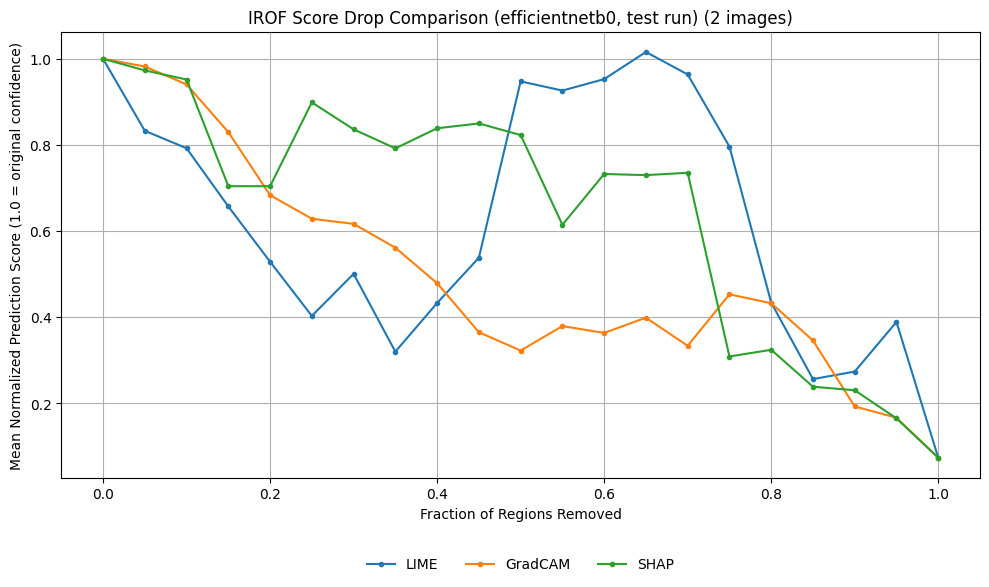

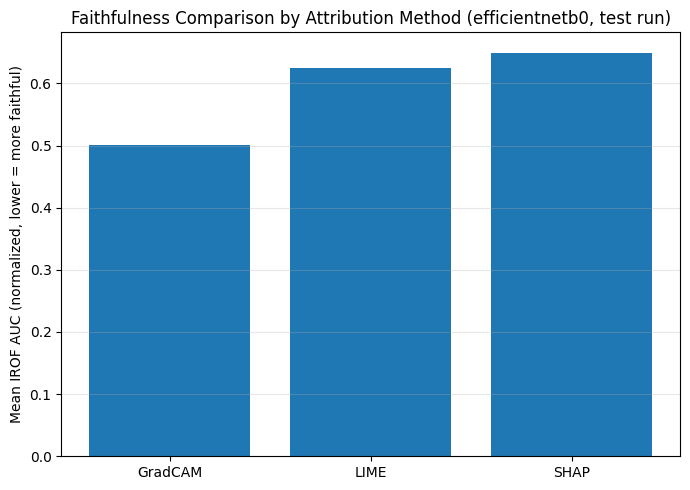


=== Combined IROF summary (all models) ===


,model,method,mean_irof_auc,std_irof_auc,n_images
0,efficientnetb0,GradCAM,0.5008,0.3239,2
1,efficientnetb0,LIME,0.6250,0.0654,2
2,efficientnetb0,SHAP,0.6496,0.2139,2
5,resnet50,SHAP,0.5245,0.1013,2
3,resnet50,GradCAM,0.5451,0.0045,2
4,resnet50,LIME,0.5956,0.1606,2


In [45]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
_trapz = getattr(np, "trapezoid", None) or np.trapz

all_irof_dfs = []
irof_curves_by_model = {}

for model_name in["resnet50", "efficientnetb0"]:
    print(f"\n{'='*60}\n  Faithfulness (IROF) | Model: {model_name}\n{'='*60}")

    drive_weight_path = os.path.join(drive_model_dir, f"{model_name}_best_model.pth")
    model = load_model(model_name, drive_weight_path, device)

    method_maps = load_attribution_maps(SAVE_DIR, model_name)
    N_FAITHFULNESS_IMAGES = len(next(iter(method_maps.values())))
    faithfulness_samples = idrid_subset[:N_FAITHFULNESS_IMAGES]

    predicted_labels = get_predicted_labels(model, faithfulness_samples, device)

    print(f"Running faithfulness (IROF) test run on {N_FAITHFULNESS_IMAGES} images ")

    full_irof_df, irof_curves, irof_random_curves = run_irof_evaluation(
        model, faithfulness_samples, predicted_labels, method_maps
    )

    full_irof_df['model'] = model_name
    all_irof_dfs.append(full_irof_df)
    irof_curves_by_model[model_name] = irof_curves

    print(f"\nCollected {len(full_irof_df)} IROF measurements")

    irof_summary = summarize_and_save_irof(
        full_irof_df,
        results_dir="/data/aveera/results",
        tag=f"{model_name}_test"
    )

    print(f"\n=== Faithfulness (IROF) summary | {model_name} ===")
    print("    (lower mean_irof_auc = confidence drops faster once top-attributed regions")
    print("     are removed = more faithful explanation)\n")
    display(irof_summary)

    plot_irof_curves(irof_curves, N_FAITHFULNESS_IMAGES, title_suffix=f" ({model_name}, test run)")
    print()
    plot_irof_bar(irof_summary, title_suffix=f" ({model_name}, test run)")

full_irof_df_all_models = pd.concat(all_irof_dfs, ignore_index=True)
combined_irof_summary = (
    full_irof_df_all_models.groupby(['model', 'method'])
    .agg(mean_irof_auc=('irof_auc', 'mean'), std_irof_auc=('irof_auc', 'std'), n_images=('irof_auc', 'count'))
    .reset_index()
    .sort_values(['model', 'mean_irof_auc'])
)

combined_irof_summary['mean_irof_auc'] = combined_irof_summary['mean_irof_auc'].round(4)
combined_irof_summary['std_irof_auc'] = combined_irof_summary['std_irof_auc'].round(4)

print("\n=== Combined IROF summary (all models) ===")
display(combined_irof_summary)

In [46]:
RESULTS_DIR = "/data/aveera/results"
combined_irof_summary.to_csv(os.path.join(RESULTS_DIR, "irof_summary_all_models.csv"), index=False)

# **Interpretation of the IROF Score Curve**
The displayed score curve illustrates how the model’s output score changes when important image regions are gradually masked. The regions are sorted based on their estimated importance according to the chosen attribution method and then removed step by step.

An ideal score curve would show a continuous and steady decline. This would indicate that the model strongly relies on these regions for its prediction. An unstable or fluctuating curve should not necessarily be interpreted as an error but rather as a possible indication of a robust model or a broadly distributed attribution.

In this case, the score curve shows an unusual pattern. Instead of decreasing steadily, the score goes up and down a lot. There are two possible reasons for this:

1. The model appears to be highly robust to the removal of individual regions and is able to extract relevant information from the remaining areas.

2. The selected attribution method (eg. LIME) distributes importance relatively evenly across many regions, resulting in less focused and highly localized key areas.

In [47]:
def explain_gradcam(model, inputs, targets, **kwargs):
    maps = []
    eng = get_engine_for(model)  # use the model Quantus actually passed in, not a stray global

    for img, target in zip(inputs, targets):
        img_tensor = torch.from_numpy(img).float()

        gradcam = eng.compute_gradcam(
            img_tensor.unsqueeze(0).to(eng.device),
            int(target)
        )

        maps.append(gradcam)

    return np.stack(maps)[:, None, :, :]


def explain_lime(model, inputs, targets, **kwargs):
    maps = []
    eng = get_engine_for(model)

    for img, target in zip(inputs, targets):
        img_tensor = torch.from_numpy(img).float()

        raw = eng.unnormalize_to_uint8(img_tensor)

        explanation = eng.compute_lime(raw, int(target))
        heatmap = eng.get_lime_heatmap(explanation, int(target))

        maps.append(heatmap)

    return np.stack(maps)[:, None, :, :]


def explain_shap(model, inputs, targets, **kwargs):
    maps = []
    eng = get_engine_for(model)

    for img, target in zip(inputs, targets):
        img_tensor = torch.from_numpy(img).float()

        raw = eng.unnormalize_to_uint8(img_tensor)

        shap_values = eng.compute_shap(raw, target_class=int(target), all_classes=False)
        heatmap, _ = eng.get_shap_heatmap(shap_values, class_position=0)

        maps.append(heatmap)

    return np.stack(maps)[:, None, :, :]


explain_funcs = {
    "GradCAM": explain_gradcam,
    "LIME": explain_lime,
    "SHAP": explain_shap,
}

**We use the default Max-Sensitivity parameter choices:**
  -nr_samples =10
  -lower_bound=0.2

In [ ]:
N_TEST = 10
maxsens_samples = idrid_subset[:N_TEST]

now = datetime.now().strftime("%Y-%m-%d")
OUTPUT_DIR = "/data/aveera/results"
os.makedirs(OUTPUT_DIR, exist_ok=True)

all_maxsens_rows = []

for model_name in ["resnet50", "efficientnetb0"]:
    print(f"\n{'='*60}\n  MaxSensitivity Evaluation | Model: {model_name}\n{'='*60}")

    drive_weight_path = os.path.join(drive_model_dir, f"{model_name}_best_model.pth")
    model = load_model(model_name, drive_weight_path, device)

    engine = AttributionEngine(model, device)
    _engine_cache.clear()  
    _engine_cache[id(model)] = engine

    input_tensors = []
    for raw_img_np, _ in maxsens_samples:
        image_np = raw_img_np.astype(np.float32) / 255.0
        t = preprocess_image(image_np, mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
        input_tensors.append(t.squeeze(0))
    input_batch = torch.stack(input_tensors).to(device)

    x_batch = input_batch.cpu().numpy()
    y_batch = get_predicted_labels(model, maxsens_samples, device)

    model_rows = []  # per-model rows, saved incrementally

    for method, explain_func in sorted(explain_funcs.items()):
        print(f"  Computing MaxSensitivity for: {method} ({model_name})")

        np.random.seed(SEED)
        random.seed(SEED)
        torch.manual_seed(SEED)

        a_list = []
        for i in range(x_batch.shape[0]):
            a_i = explain_func(model, x_batch[i:i+1], y_batch[i:i+1])
            a_list.append(a_i[0])
        a_batch = np.stack(a_list)
        del a_list
        gc.collect()

        metric = MaxSensitivity(
            nr_samples=10,
            lower_bound=0.2,
            norm_numerator=norm_func.fro_norm,
            norm_denominator=norm_func.fro_norm,
            similarity_func=similarity_func.difference,
        )

        try:
            max_sens = metric(
                model=model,
                x_batch=x_batch,
                y_batch=y_batch,
                a_batch=a_batch,
                device=device,
                explain_func=explain_func,
            )

            for img_idx, score in enumerate(max_sens):
                row = {
                    'model':           model_name,
                    'method':          method,
                    'image_index':     img_idx,
                    'max_sensitivity': float(score),
                }
                model_rows.append(row)
                all_maxsens_rows.append(row)

        except Exception as e:
            print(f"Error in method {method} for model {model_name}: {e}")

        finally:
            del a_batch
            if 'max_sens' in dir():
                del max_sens
            gc.collect()
            if device.type == "cuda":
                torch.cuda.empty_cache()

    # Save this model's results immediately so partial progres survives
    model_df = pd.DataFrame(model_rows)
    model_df.to_csv(os.path.join(OUTPUT_DIR, f'maxsens_{model_name}_{now}.csv'), index=False)
    print(f"  Saved {model_name} results to maxsens_{model_name}_{now}.csv")

    # Free the model and engine before moving to the next one
    del model, engine
    _engine_cache.clear()
    gc.collect()
    if device.type == "cuda":
        torch.cuda.empty_cache()


  MaxSensitivity Evaluation | Model: resnet50


  Computing MaxSensitivity for: GradCAM (resnet50)


  Computing MaxSensitivity for: LIME (resnet50)



  0%|          | 0/1000 [00:00<?, ?it/s]


  1%|          | 9/1000 [00:00<00:11, 84.09it/s]

...

  Computing MaxSensitivity for: SHAP (efficientnetb0)


,model,method,image_index,max_sensitivity
0,resnet50,GradCAM,0,0.196395
1,resnet50,LIME,0,0.835882
2,resnet50,SHAP,0,0.433616
3,efficientnetb0,GradCAM,0,0.160283
4,efficientnetb0,LIME,0,0.975211
5,efficientnetb0,SHAP,0,0.316688



=== MaxSensitivity summary -- mean score per model/method ===
    (lower mean_max_sensitivity = explanation changes less under small input
     perturbations = more robust explanation)



,model,method,mean_max_sensitivity,std_max_sensitivity,n_images
0,efficientnetb0,GradCAM,0.1603,NaN,1
2,efficientnetb0,SHAP,0.3167,NaN,1
1,efficientnetb0,LIME,0.9752,NaN,1
3,resnet50,GradCAM,0.1964,NaN,1
5,resnet50,SHAP,0.4336,NaN,1
4,resnet50,LIME,0.8359,NaN,1



Saved per-image results to maxsens_full_2026-09-09.csv
Saved summary to maxsens_summary_2026-09-09.csv


In [ ]:
full_maxsens_df = pd.DataFrame(all_maxsens_rows)
display(full_maxsens_df)

maxsens_summary = (
    full_maxsens_df
    .groupby(['model', 'method'])['max_sensitivity']
    .agg(['mean', 'std', 'count'])
    .reset_index()
    .rename(columns={'mean': 'mean_max_sensitivity', 'std': 'std_max_sensitivity', 'count': 'n_images'})
)
maxsens_summary['mean_max_sensitivity'] = maxsens_summary['mean_max_sensitivity'].round(4)
maxsens_summary['std_max_sensitivity'] = maxsens_summary['std_max_sensitivity'].round(4)
maxsens_summary = maxsens_summary.sort_values(['model', 'mean_max_sensitivity'])

print("\n=== MaxSensitivity summary -- mean score per model/method ===")
print("    (lower mean_max_sensitivity = explanation changes less under small input")
print("     perturbations = more robust explanation)\n")
display(maxsens_summary)


now = datetime.now().strftime("%Y-%m-%d")
OUTPUT_DIR = "/data/aveera/results"
os.makedirs(OUTPUT_DIR, exist_ok=True)
full_maxsens_df.to_csv(os.path.join(OUTPUT_DIR, f'maxsens_full_{now}.csv'), index=False)
maxsens_summary.to_csv(os.path.join(OUTPUT_DIR, f'maxsens_summary_{now}.csv'), index=False)
print(f"\nSaved per-image results to maxsens_full_{now}.csv")
print(f"Saved summary to maxsens_summary_{now}.csv")

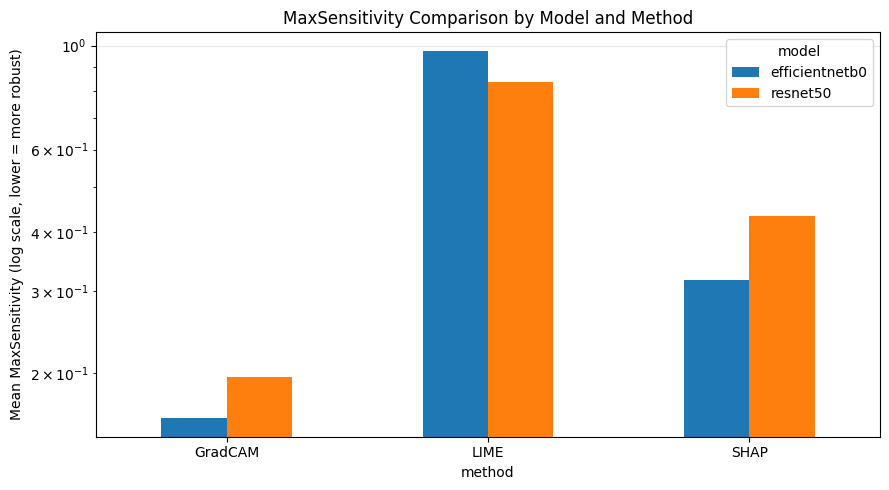

In [49]:
plt.figure(figsize=(9, 5))
pivot = maxsens_summary.pivot(index='method', columns='model', values='mean_max_sensitivity')
pivot.plot(kind='bar', ax=plt.gca())
plt.yscale("log")
plt.ylabel("Mean MaxSensitivity (log scale, lower = more robust)")
plt.title(f"MaxSensitivity Comparison by Model and Method")
plt.xticks(rotation=0)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()
